<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9615.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import itertools
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import Adam
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)

# Завдання 1. Реалізація моделі CRF для задачі про кубики

> Реалізуйте модель надану у теоретичній частині та проведіть відповідний експеримент.

In [ ]:
class CRF(nn.Module):
    def __init__(self, n_dice, log_likelihood):
        super(CRF, self).__init__()
        self.n_states = n_dice
        self.transition = nn.init.normal_(nn.Parameter(torch.randn(n_dice, n_dice + 1)), -1, 0.1)
        self.loglikelihood = log_likelihood

    def to_scalar(self, var):
        return var.view(-1).data.tolist()[0]

    def argmax(self, vec):
        _, idx = torch.max(vec, 1)
        return self.to_scalar(idx)

    def log_sum_exp(self, vec):
        max_score = vec[0, self.argmax(vec)]
        max_score_broadcast = max_score.view(1, -1).expand(1, vec.size()[1])
        return max_score + torch.log(torch.sum(torch.exp(vec - max_score_broadcast)))

    def _data_to_likelihood(self, rolls):
        return torch.FloatTensor(self.loglikelihood[rolls])

    def _compute_likelihood_numerator(self, loglikelihoods, states):
        prev_state = self.n_states
        score = torch.Tensor([0])
        for index, state in enumerate(states):
            score = score + self.transition[state, prev_state] + loglikelihoods[index, state]
            prev_state = state
        return score

    def _compute_likelihood_denominator(self, loglikelihoods):
        prev_alpha = self.transition[:, self.n_states].reshape(1, -1) + loglikelihoods[0].view(1, -1)
        for roll in loglikelihoods[1:]:
            alpha_t = []
            for next_state in range(self.n_states):
                feature_function = self.transition[next_state, :self.n_states].view(1, -1) + \
                    roll[next_state].view(1, -1).expand(1, self.n_states)
                alpha_t_next_state = prev_alpha + feature_function
                alpha_t.append(self.log_sum_exp(alpha_t_next_state))
            prev_alpha = torch.stack(alpha_t).view(1, -1)
        return self.log_sum_exp(prev_alpha)

    def _viterbi_algorithm(self, loglikelihoods):
        argmaxes = []
        prev_delta = self.transition[:, self.n_states].reshape(1, -1) + loglikelihoods[0].view(1, -1)
        for roll in loglikelihoods[1:]:
            local_argmaxes = []
            next_delta = []
            for next_state in range(self.n_states):
                feature_function = self.transition[next_state, :self.n_states].view(1, -1) + \
                    roll[next_state] + prev_delta
                most_likely_state = self.argmax(feature_function)
                score = feature_function[0][most_likely_state]
                next_delta.append(score)
                local_argmaxes.append(most_likely_state)
            prev_delta = torch.stack(next_delta).view(1, -1)
            argmaxes.append(local_argmaxes)
        final_state = self.argmax(prev_delta)
        final_score = prev_delta[0][final_state]
        path_list = [final_state]
        for states in reversed(argmaxes):
            final_state = states[final_state]
            path_list.append(final_state)
        return np.array(path_list[::-1]), final_score

    def neg_log_likelihood(self, rolls, states):
        loglikelihoods = self._data_to_likelihood(rolls)
        states = torch.LongTensor(states)
        sequence_loglik = self._compute_likelihood_numerator(loglikelihoods, states)
        denominator = self._compute_likelihood_denominator(loglikelihoods)
        return denominator - sequence_loglik

    def forward(self, rolls):
        loglikelihoods = self._data_to_likelihood(rolls)
        return self._viterbi_algorithm(loglikelihoods)

def crf_train_loop(model, optimizer, rolls, targets, n_epochs, verbose=True):
    epoch_losses = []
    N = rolls.shape[0]
    for epoch in range(n_epochs):
        batch_loss, losses = [], []
        for index, (roll, labels) in enumerate(zip(rolls, targets)):
            batch_loss.append(model.neg_log_likelihood(roll, labels))
            if index % 50 == 0:
                ll = torch.cat(batch_loss).mean()
                optimizer.zero_grad()
                ll.backward()
                optimizer.step()
                losses.append(ll.item())
                batch_loss = []
        epoch_losses.append(np.mean(losses))
        if verbose:
            print("Епоха {}: середня втрата {:.4f}".format(epoch + 1, epoch_losses[-1]))
    return epoch_losses

Реалізація взята з теорії: матриця переходів `transition` розміром 2 на 3 (перші два стовпці відповідають попередньому стану «правильний» та «зважений», третій є початковим станом), чисельник логарифмічної правдоподібності послідовності, знаменник через прохід вперед (forward-частина алгоритму «вперед-назад») та алгоритм Вітербі. Додатково виправлено кілька дрібниць: `torch.nn.init.normal` замінено на `normal_`, у навчальному циклі градієнти обнуляються перед кожним кроком оптимізатора (у теорії `zero_grad` викликається один раз за епоху, тому градієнти накопичувались би), шлях Вітербі повертається у прямому порядку (у теорії він виходить розвернутим), а в алгоритмі Вітербі логарифмічна правдоподібність спостереження береться для нового стану `roll[next_state]` (у теорії додається весь вектор `roll`, тобто для кожного попереднього стану додавалась правдоподібність не того стану, і прогнози були гіршими за просте правило).

In [ ]:
fair_dice = np.array([1/6] * 6)
loaded_dice = np.array([0.04, 0.04, 0.04, 0.04, 0.04, 0.8])
probabilities = {'fair': fair_dice, 'loaded': loaded_dice}
transition_mat = {'fair': np.array([0.8, 0.2, 0.0]),
                  'loaded': np.array([0.35, 0.65, 0.0]),
                  'start': np.array([0.5, 0.5, 0.0])}
states = ['fair', 'loaded', 'start']
state2ix = {'fair': 0, 'loaded': 1, 'start': 2}

log_likelihood = np.hstack([np.log(fair_dice).reshape(-1, 1), np.log(loaded_dice).reshape(-1, 1)])
print(log_likelihood)

def simulate_data(n_timesteps):
    data = np.zeros(n_timesteps)
    prev_state = 'start'
    state_list = np.zeros(n_timesteps)
    for n in range(n_timesteps):
        next_state = np.random.choice(states, p=transition_mat[prev_state])
        state_list[n] = state2ix[next_state]
        next_data = np.random.choice([0, 1, 2, 3, 4, 5], p=probabilities[next_state])
        data[n] = next_data
        prev_state = next_state
    return data, state_list

n_obs = 15
rolls = np.zeros((5000, n_obs)).astype(int)
targets = np.zeros((5000, n_obs)).astype(int)
for i in range(5000):
    data, dices = simulate_data(n_obs)
    rolls[i] = data.reshape(1, -1).astype(int)
    targets[i] = dices.reshape(1, -1).astype(int)

print(rolls[0], targets[0])

[[-1.79175947 -3.21887582]
 [-1.79175947 -3.21887582]
 [-1.79175947 -3.21887582]
 [-1.79175947 -3.21887582]
 [-1.79175947 -3.21887582]
 [-1.79175947 -0.22314355]]


[5 5 5 5 5 5 5 0 4 5 5 5 3 5 2] [1 1 1 1 1 1 1 0 0 0 1 1 0 0 0]


Дані імітуються за ймовірностями з теорії: перший кубик справедливий з ймовірністю 0.5, після справедливого наступний справедливий з ймовірністю 0.8, після зваженого наступний зважений з ймовірністю 0.65 (за умовою 0.35 для переходу зваженого в справедливий). Створюється 5000 послідовностей по 15 кидків. Значення кубика кодуються числами від 0 до 5 (число 5 означає шістку), а стани числами 0 (справедливий) та 1 (зважений).

In [ ]:
model = CRF(2, log_likelihood)
optimizer = Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
history = crf_train_loop(model, optimizer, rolls, targets, 10)
torch.save(model.state_dict(), "./checkpoint.pt")

Епоха 1: середня втрата 6.8902


Епоха 2: середня втрата 6.4753


Епоха 3: середня втрата 6.1864


Епоха 4: середня втрата 5.9922


Епоха 5: середня втрата 5.8663


Епоха 6: середня втрата 5.7880


Епоха 7: середня втрата 5.7414


Епоха 8: середня втрата 5.7149


Епоха 9: середня втрата 5.7005


Епоха 10: середня втрата 5.6930


In [ ]:
model.load_state_dict(torch.load("./checkpoint.pt"))
for _ in range(2):
    data, dices = simulate_data(15)
    test_rolls = data.reshape(1, -1).astype(int)
    test_targets = dices.reshape(1, -1).astype(int)
    print("кидки:        ", test_rolls[0])
    print("передбачення: ", model.forward(test_rolls[0])[0])
    print("справжні стани:", test_targets[0])

кидки:         [5 5 5 2 5 5 4 2 1 3 3 1 5 1 1]
передбачення:  [1 1 1 1 1 1 0 0 0 0 0 0 0 0 0]
справжні стани: [1 0 0 0 1 1 0 0 0 0 0 0 1 0 0]
кидки:         [4 5 3 5 1 3 5 5 4 5 1 1 3 5 5]
передбачення:  [0 0 0 0 0 0 1 1 0 0 0 0 0 1 1]
справжні стани: [0 1 0 0 0 0 0 1 0 0 0 0 0 1 1]


Модель навчилась: середня негативна логарифмічна правдоподібність за 10 епох впала з 6.89 до 5.69, причому останні епохи майже не змінюють її (5.70, 5.69). Параметри збережено у файл через `torch.save(model.state_dict(), ...)` і завантажено назад через `load_state_dict`, після чого алгоритм Вітербі застосовано до двох нових послідовностей з 15 кидків. Передбачені стани частково збігаються зі справжніми: серії шісток визначаються як зважений кубик, а решта як справедливий. Помилки трапляються там, де шістка випала на справедливому кубику або не випала на зваженому, і їх не можна відрізнити лише за самими кидками.

# Завдання 2. Матриця переходу та тривалість навчання

> Як виглядає орієнтовна матриця переходу? Проаналізуйте отримані результати. Спробуйте збільшити тривалість навчання, як зміниться результат? Зробіть висновки та вкажіть це у звіті.

In [ ]:
np.set_printoptions(precision=3, suppress=True)
print("exp(T) після 10 епох (рядки: наступний стан, стовпці: попередній стан правильний, зважений, початок):")
print(np.exp(list(model.parameters())[0].data.numpy()))

true_T = np.array([[0.8, 0.35, 0.5], [0.2, 0.65, 0.5]])
print("Справжні ймовірності переходів:")
print(true_T)

exp(T) після 10 епох (рядки: наступний стан, стовпці: попередній стан правильний, зважений, початок):
[[0.641 0.245 0.317]
 [0.209 0.513 0.406]]
Справжні ймовірності переходів:
[[0.8  0.35 0.5 ]
 [0.2  0.65 0.5 ]]


In [ ]:
test_rolls_all = np.zeros((1000, n_obs)).astype(int)
test_targets_all = np.zeros((1000, n_obs)).astype(int)
for i in range(1000):
    data, dices = simulate_data(n_obs)
    test_rolls_all[i] = data.astype(int)
    test_targets_all[i] = dices.astype(int)

def viterbi_accuracy(m):
    correct = sum((m.forward(r)[0] == t).sum() for r, t in zip(test_rolls_all, test_targets_all))
    return correct / test_targets_all.size

naive = ((test_rolls_all == 5).astype(int) == test_targets_all).mean()
print("Точність простого правила «шістка означає зважений кубик»:", round(naive, 4))
print("Точність Вітербі після 10 епох:", round(viterbi_accuracy(model), 4))

Точність простого правила «шістка означає зважений кубик»: 0.821


Точність Вітербі після 10 епох: 0.8225


після 30 епох: втрата 5.6831, точність Вітербі 0.8201
[[0.658 0.263 0.328]
 [0.183 0.529 0.395]]


після 60 епох: втрата 5.6806, точність Вітербі 0.8201
[[0.657 0.304 0.356]
 [0.159 0.532 0.368]]


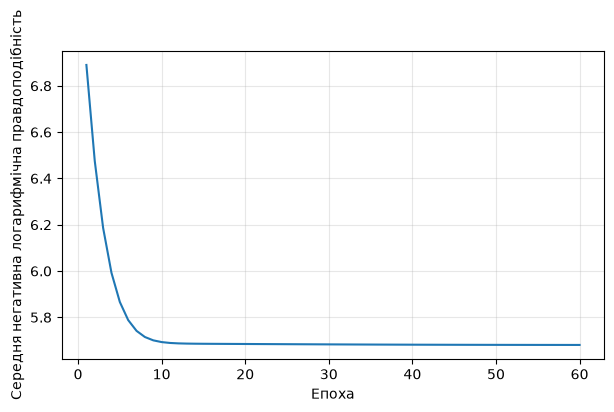

In [ ]:
rows = {10: {'втрата': history[-1], 'точність Вітербі': viterbi_accuracy(model),
             'T': np.exp(model.transition.data.numpy()).round(3).tolist()}}
all_losses = list(history)
done = 10
for target in [30, 60]:
    more = crf_train_loop(model, optimizer, rolls, targets, target - done, verbose=False)
    all_losses += more
    done = target
    rows[target] = {'втрата': more[-1], 'точність Вітербі': viterbi_accuracy(model),
                    'T': np.exp(model.transition.data.numpy()).round(3).tolist()}
    print(f"після {target} епох: втрата {more[-1]:.4f}, точність Вітербі {rows[target]['точність Вітербі']:.4f}")
    print(np.exp(model.transition.data.numpy()))

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(all_losses) + 1), all_losses)
plt.xlabel('Епоха')
plt.ylabel('Середня негативна логарифмічна правдоподібність')
plt.grid(alpha=0.3)
plt.show()

Матриця `exp(T)` після 10 епох: [[0.641, 0.245, 0.317], [0.209, 0.513, 0.406]]. Рядки це наступний стан (справедливий, зважений), стовпці попередній стан (справедливий, зважений, початок). Значення не є ймовірностями, бо в CRF вартості переходів не нормовані (суми стовпців 0.85, 0.76, 0.72), але їх співвідношення відповідає ймовірностям: якщо нормувати кожен стовпець на суму, виходить 0.754, 0.323, 0.438 для переходу в справедливий стан проти справжніх 0.8, 0.35, 0.5. Тобто модель правильно навчилась, що після справедливого кубика найімовірніше знову справедливий, після зваженого частіше зважений, а початок рівноймовірний, але оцінки поки занижені.

Після 30 епох нормовані значення стають 0.782, 0.332, 0.454, а після 60 епох 0.805, 0.364, 0.49 (матриця `exp(T)` [[0.657, 0.304, 0.356], [0.159, 0.532, 0.368]]), тобто наближаються до справжніх 0.8, 0.35, 0.5. Втрата при цьому змінюється слабко: 5.693 (10 епох), 5.683 (30 епох), 5.681 (60 епох), бо значна частина втрати це невизначеність самих даних, яку не усунути. Точність Вітербі на 1000 нових послідовностей майже не залежить від тривалості навчання: 0.8225, 0.8201 та 0.8201 і дорівнює точності простого правила «шістка означає зважений кубик» (0.821). Для цієї задачі це очікуваний результат: при обраних ймовірностях облік переходів майже не покращує розпізнавання кожного окремого кидка, але дозволяє оцінити сам процес переходів, і тривале навчання дає точніші параметри, а не кращі прогнози.

# Завдання 3. Задача генетики

> Задача генетики. Створіть модель та поясніть результат.
> Розглянемо наступну просту модель. Ця модель складається з двох станів, H (високий вміст GC) та L (низький вміст GC). Для довідки, GC: У генетиці, вміст гуаніну і цітозину (часто скорочується як «вміст ГЦ» або «вміст GC», іноді навіть як GC%) – характеристика геному будь-якого даного організму або будь-якого іншого шматка ДНК або РНК. Ми можемо, наприклад, припустити, що стан H характеризує кодоване ДНК тоді як L характеризує некодоване ДНК.
> Таким чином, модель може бути використана для прогнозування області кодування ДНК із заданої послідовності.
> Задані ймовірності (зі схеми): початок з ймовірністю 0.5 веде в H та 0.5 в L; у стані H: A 0.2, C 0.3, G 0.3, T 0.2, перехід H→H 0.5, H→L 0.5; у стані L: A 0.3, C 0.2, G 0.2, T 0.3, перехід L→L 0.6, L→H 0.4.
> Розглянемо послідовність: S = GGCACTGAA.
> Існує кілька шляхів через приховані стани (H і L), які ведуть до заданої послідовності S.
> Наприклад: P = LLHHHHLLL

In [ ]:
hidden = ['H', 'L']
start_p = {'H': 0.5, 'L': 0.5}
trans_p = {'H': {'H': 0.5, 'L': 0.5}, 'L': {'H': 0.4, 'L': 0.6}}
emit_p = {'H': {'A': 0.2, 'C': 0.3, 'G': 0.3, 'T': 0.2}, 'L': {'A': 0.3, 'C': 0.2, 'G': 0.2, 'T': 0.3}}
S = 'GGCACTGAA'

def path_probability(S, path):
    p = start_p[path[0]] * emit_p[path[0]][S[0]]
    for i in range(1, len(S)):
        p *= trans_p[path[i - 1]][path[i]] * emit_p[path[i]][S[i]]
    return p

P = 'LLHHHHLLL'
print("P(S, P = LLHHHHLLL) =", path_probability(S, P))
print("логарифм:", np.log(path_probability(S, P)))

all_paths = {''.join(p): path_probability(S, p) for p in itertools.product(hidden, repeat=len(S))}
total = sum(all_paths.values())
print("Кількість шляхів:", len(all_paths))
print("P(S) за сумою по всіх шляхах:", total)
print("P(шлях LLHHHHLLL | S) =", all_paths[P] / total)

P(S, P = LLHHHHLLL) = 6.9984e-09
логарифм: -18.7775842854461
Кількість шляхів: 512
P(S) за сумою по всіх шляхах: 3.79101603552e-06
P(шлях LLHHHHLLL | S) = 0.0018460486408995247


In [ ]:
def forward_probability(S):
    alpha = {s: start_p[s] * emit_p[s][S[0]] for s in hidden}
    for ch in S[1:]:
        alpha = {s: sum(alpha[r] * trans_p[r][s] for r in hidden) * emit_p[s][ch] for s in hidden}
    return sum(alpha.values())

def viterbi(S):
    delta = {s: start_p[s] * emit_p[s][S[0]] for s in hidden}
    back = []
    for ch in S[1:]:
        new_delta, pointers = {}, {}
        for s in hidden:
            best = max(hidden, key=lambda r: delta[r] * trans_p[r][s])
            new_delta[s] = delta[best] * trans_p[best][s] * emit_p[s][ch]
            pointers[s] = best
        delta = new_delta
        back.append(pointers)
    last = max(hidden, key=lambda s: delta[s])
    path = [last]
    for pointers in reversed(back):
        path.append(pointers[path[-1]])
    return ''.join(path[::-1]), delta[last]

print("P(S) за алгоритмом вперед:", forward_probability(S))
best_path, best_prob = viterbi(S)
print("Найімовірніший шлях за Вітербі:", best_path, ", ймовірність:", best_prob)
print("Повний перебір:", max(all_paths, key=all_paths.get), max(all_paths.values()))

top = sorted(all_paths.items(), key=lambda kv: -kv[1])[:6]
print(pd.DataFrame(top, columns=['шлях', 'P(S, шлях)']).assign(
    **{'P(шлях | S)': lambda d: d['P(S, шлях)'] / total}).to_string(index=False))
print('LLHHHHLLL у рейтингу шляхів:', sorted(all_paths, key=all_paths.get, reverse=True).index(P) + 1, 'з', len(all_paths))

P(S) за алгоритмом вперед: 3.791016035520001e-06
Найімовірніший шлях за Вітербі: HHHLLLLLL , ймовірність: 4.251527999999999e-08
Повний перебір: HHHLLLLLL 4.2515279999999984e-08
     шлях   P(S, шлях)  P(шлях | S)
HHHLLLLLL 4.251528e-08     0.011215
HHHLHLLLL 3.542940e-08     0.009346
HHHLLLHLL 3.542940e-08     0.009346
HHLLLLLLL 3.401222e-08     0.008972
HHHHHLLLL 2.952450e-08     0.007788
HHHLHLHLL 2.952450e-08     0.007788
LLHHHHLLL у рейтингу шляхів: 207 з 512


Для заданої моделі H та L ймовірність послідовності S = GGCACTGAA і шляху P = LLHHHHLLL дорівнює 6.998 · 10⁻⁹ (логарифм −18.78), що є добутком початкової ймовірності, ймовірностей переходів і ймовірностей спостережуваних нуклеотидів у відповідних станах. Сума за всіма 512 можливими шляхами дає ймовірність самої послідовності P(S) = 3.791 · 10⁻⁶, і та сама величина виходить за алгоритмом вперед, тож ймовірність шляху LLHHHHLLL за умови послідовності становить лише 0.0018, і цей шлях посідає 207 місце з 512. Найімовірніший шлях за алгоритмом Вітербі: HHHLLLLLL з ймовірністю 4.25 · 10⁻⁸ (ймовірність за умови S 0.011), і він збігається з повним перебором. Пояснення: на початку послідовності стоїть GGC, де багато G та C, ці нуклеотиди в стані H мають вищу ймовірність (0.3 проти 0.2), тому перші три позиції належать стану H, а далі ACTGAA містить більше A та T, які ймовірніші в стані L, до того ж стан L стійкіший (перехід L→L 0.6 проти H→H 0.5). Навіть найкращий шлях має ймовірність лише близько 1%, бо різниця між станами невелика, і багато шляхів мають співмірні ймовірності.

# Висновки

У цьому практикумі ми навчились реалізовувати умовне випадкове поле (CRF) у PyTorch: задавати матрицю переходів, обчислювати чисельник і знаменник логарифмічної правдоподібності послідовності (знаменник проходом вперед за алгоритмом «вперед-назад»), навчати модель градієнтним спуском і знаходити найімовірнішу послідовність міток алгоритмом Вітербі. Метою роботи було засвоїти принцип роботи ймовірнісних моделей CRF та Вітербі, і її досягнуто.

**Результати.** Модель кубиків навчилась за 10 епох (втрата 6.89 → 5.69), а нормована матриця переходів наблизилась до справжньої: [0.754, 0.323, 0.438] проти [0.8, 0.35, 0.5]. Збільшення тривалості навчання до 30 і 60 епох уточнило ці значення (0.782, 0.332, 0.454, а потім 0.805, 0.364, 0.49), але втрата змінилась слабко (5.693, 5.683, 5.681), а точність Вітербі залишилась на рівні 0.82, що дорівнює простому правилу «шістка означає зважений кубик» (0.821). Тому довше навчання доцільне для точнішої оцінки параметрів, але не для кращих прогнозів. У коді теорії виявлено помилку: в алгоритмі Вітербі додавалась правдоподібність не того стану (весь вектор `roll`), через що точність Вітербі була лише 0.74 при істинних параметрах, і після виправлення (`roll[next_state]`) вона зросла до 0.82. У задачі генетики за заданою моделлю найімовірнішим шляхом для GGCACTGAA є HHHLLLLLL (ймовірність 4.25 · 10⁻⁸), а наведений у завданні шлях LLHHHHLLL у 6 разів менш імовірний за нього і посідає 207 місце з 512.

# Контрольні питання

**1. У чому суть Conditional Random Fields?**

Умовне випадкове поле (conditional random field, CRF) це стандартна модель для прогнозування найбільш ймовірної послідовності міток, яка відповідає послідовності входів, і одна з ймовірнісних графічних моделей. Вибирати найімовірнішу мітку на кожному кроці окремо достатньо лише тоді, коли попередній вибір не впливає на наступний. Наприклад, якщо після справедливого кубика із ймовірністю 0.9 береться зважений, то за теоремою Байєса ймовірність того, що кубик справедливий, коли випало 3, лише 0.32, і краще передбачити зважений. Тому CRF враховує взаємозалежність елементів послідовності. Модель задається параметрами, у простій задачі це матриця переходу, яка містить вартості переходу між мітками в послідовних кроках (з окремим стовпцем для першого кроку). Параметри оцінюються мінімізацією негативної логарифмічної правдоподібності за навчальними даними: у чисельнику стоїть добуток ймовірностей P(xi|yi) спостережень за поточною міткою та вартостей переходів T(yi|yi-1) для справжньої послідовності міток, а у знаменнику сума таких добутків за всіма можливими послідовностями міток (для довжини 15 це 2 у степені 15 доданків). Знаменник обчислюється ефективно за допомогою алгоритму «вперед-назад», бо поточна мітка залежить лише від попередньої, а градієнти для навчання дає автоматичне диференціювання PyTorch. Для прогнозування використовується алгоритм Вітербі. CRF застосовують в обробці природної мови (наприклад, для розпізнавання назв, коли належність слова «New» до назви залежить від наступного слова «York») та в обробці зображень для згладжування результатів сегментації.

**2. Що являє собою алгоритм Viterbi?**

Алгоритм Вітербі знаходить найімовірнішу послідовність прихованих міток для заданої послідовності спостережень. Наївний підхід, обчислення ймовірності всіх можливих послідовностей, нерозв'язний навіть для послідовностей середньої довжини. Алгоритм тісно пов'язаний з проходом вперед, який використовується для знаменника правдоподібності, але замість суми по попередніх станах бере максимум. На першому кроці для кожного стану рахується оцінка з вартості початкового переходу та логарифмічної правдоподібності першого спостереження. На кожному наступному кроці для кожного нового стану серед усіх попередніх станів вибирається той, що дає найбільшу суму накопиченої оцінки та вартості переходу, і додається логарифмічна правдоподібність спостереження, при цьому запам'ятовується, який попередній стан було вибрано (argmax). Після останнього кроку вибирається стан з найбільшою оцінкою, а шлях відновлюється зворотним проходом по збережених вказівниках. Так найкращу послідовність міток вдається знайти за кількість операцій, пропорційну довжині послідовності, а не кількості всіх можливих послідовностей.